# GraphST

- **Creator**: Sebastian Birk (<sebastian.birk@helmholtz-munich.de>)
- **Date of Creation:** 11.01.2023
- **Date of Last Modification:** 02.04.2026 (Sebastian Birk; <sebastian.birk@helmholtz-munich.de>)

- The GraphST source code is available at https://github.com/JinmiaoChenLab/GraphST.
- The corresponding preprint is "Long, Y. et al. DeepST: A versatile graph contrastive learning framework for spatially informed clustering, integration, and deconvolution of spatial transcriptomics. Preprint at https://doi.org/10.1101/2022.08.02.502407".
- The workflow of this notebook follows the tutorial from https://deepst-tutorials.readthedocs.io/en/latest/Tutorial%204_Horizontal%20Integration.html.

- Run this notebook in the nichecompass-reproducibility environment, installable from ```('../../../envs/environment.yaml')```.

## 1. Setup

### 1.1 Import Libraries

In [25]:
import sys
sys.path.append("../../utils")

In [1]:
import anndata as ad
import os
import warnings
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
import matplotlib.pyplot as plt
import squidpy as sq

In [2]:
import ot

In [3]:
import paste as pst

In [4]:
import time

In [5]:
from GraphST import GraphST

In [28]:
from analysis_utils import *
from benchmarking_utils import max_overlap_plot

### 1.2 Configure Paths

In [6]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

In [30]:
n_pcs = None
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'

### 1.3 Run Notebook Setup

In [8]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [9]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [10]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [11]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [12]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/graphst', exist_ok=True)

### 1.4 Configure Paths and Directories

In [13]:
st_data_gold_folder_path = "../../../datasets/st_data/gold"
st_data_results_folder_path = "../../../datasets/st_data/results" 
figure_folder_path = f"../../../figures"
benchmarking_folder_path = "../../../artifacts/sample_integration_method_benchmarking"

# Create required directories
os.makedirs(st_data_gold_folder_path, exist_ok=True)
os.makedirs(st_data_results_folder_path, exist_ok=True)

## 1.5 Define Functions

In [14]:
def _combine_neighbor_graphs(adata: ad.AnnData,
                             n_neighs,
                             radius,
                             delaunay: bool,
                             include_self_loop: bool,
                             ) -> ad.AnnData:
    """
    Helper function to combine neighbor graphs computed using different
    methods.
    """
    if n_neighs is not None:
        # Compute knn spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                n_neighs=n_neighs,
                                set_diag=include_self_loop,
                                ) 
        knn_conn = adata.obsp['spatial_connectivities']  
    if radius is not None:
        # Compute spatial neighborhood graph with radius
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                radius=radius,
                                set_diag=include_self_loop,
                                )
        radius_conn = adata.obsp['spatial_connectivities'] 
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
    if delaunay:
        # Compute spatial neighborhood graph with delaunay triangulation
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=include_self_loop,
                                )
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
        if radius is not None:
            adata.obsp[
                'spatial_connectivities'] = radius_conn.multiply(
                    adata.obsp['spatial_connectivities'])

    return adata


def construct_neighbor_graph(adata: ad.AnnData,
                             n_neighs,
                             radius,
                             delaunay,
                             include_self_loop,
                             batch_key=None,
                             compute_neighbor_counts=False,
                             ) -> ad.AnnData:
    """
    Compute neighbor graph and optionally aggregate cell features across
    neighbors.

    Parameters
    ----------
    adata:
        AnnData object with spatial coordinates available in
        `adata.obsm['spatial']`.
    n_neighs:
        If specified, use `n_neighs` to compute the neighborhood graph.
        If 'radius' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    radius:
        If specified, use `radius` to compute the neighborhood graph. If
        'n_neighs' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    delaunay:
        If 'True', compute the neighborhood graph by delaunay
        triangulation. If 'n_neighs' or 'radius' are also specified, an
        intersection neighborhood graph will be computed.
    include_self_loop:
        If 'True', include cell itself in neighborhood graph.
    batch_key:
        Key in adata.obs where the batch is stored in case the AnnData
        contains multiple batches. This is important to specify if there
        are multiple batches in the AnnData to perform separate neighbor
        graph computation and then concatenate.
    compute_neighbor_counts:
        If 'True', aggregate counts across neighborhood and store in
        `adata.layers['X_neighborhood']`.

    Returns
    ----------
    adata:
        AnnData object with aggregated counts available in
        `adata.layers['X_neighborhood']`.
    """
    if batch_key is not None:
        # Get ordered batches
        first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index
        batches = adata.obs.iloc[first_idx][batch_key].tolist()
        adata_batch_list = []

        for batch in batches:
            print(f"\nProcessing batch {batch}...")
            print("Loading data...")
            adata_batch = adata[adata.obs[batch_key] == batch]

            print("Computing spatial neighborhood graph...")
            adata_batch = _combine_neighbor_graphs(
                adata_batch,
                n_neighs,
                radius,
                delaunay,
                include_self_loop)
            adata_batch_list.append(adata_batch)

        # Block-diagonal concatenate graphs (disconnected components)
        adata.obsp['spatial_connectivities'] = sp.block_diag(
            [a.obsp['spatial_connectivities'] for a in adata_batch_list],
            format="csr",
        )    
    else:
        adata = _combine_neighbor_graphs(
            adata,
            n_neighs,
            radius,
            delaunay,
            include_self_loop)           
    
    if compute_neighbor_counts:
        adata.layers['X_neighborhood'] = (
            adata.obsp['spatial_connectivities'].T @ adata.X)

    return adata

## 2. GraphST Model

In [15]:
# Run device. By default, the package is implemented on 'cpu'. It is recommended to use GPU.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [16]:
# Define dataset params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
batch_key = 'batch'
label_keys = [niche_key]

In [17]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/nfs/team361/sb75/.venvs/graphst/lib/python3.8/site-packages/anndata/_core/merge.py:1111: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


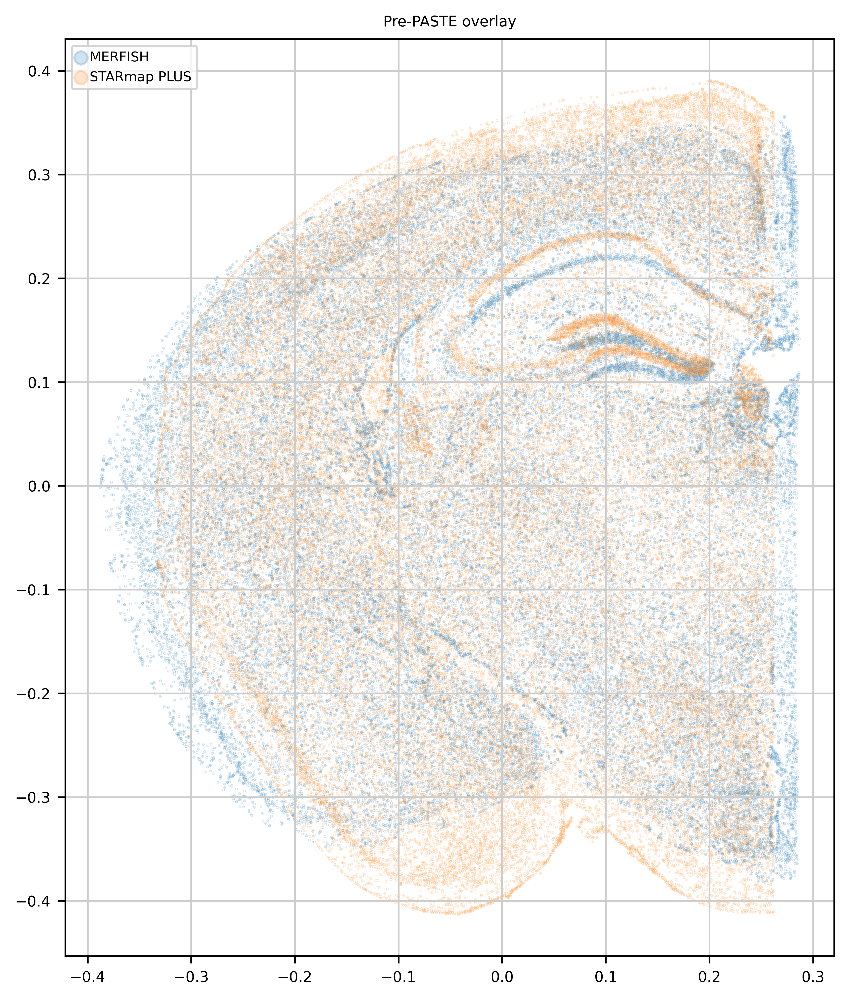

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ── 1. Flip MERFISH y-axis (raw coords have inverted y) ──
coords0 = adata_list[0].obsm['spatial'].copy().astype(float)
coords0[:, 1] = -coords0[:, 1]
adata_list[0].obsm['spatial'] = coords0

# ── 2. Center and normalize both to unit diagonal ──
for a in adata_list:
    coords = a.obsm['spatial'].copy().astype(float)
    coords -= coords.mean(axis=0)
    diag = np.sqrt((coords[:, 0].max() - coords[:, 0].min())**2 +
                   (coords[:, 1].max() - coords[:, 1].min())**2)
    coords /= diag
    a.obsm['spatial'] = coords

# ── 3. Rotate and flip ──
def apply_rotation(coords, angle_deg, flip=None):
    x, y = coords[:, 0], coords[:, 1]
    theta = np.radians(angle_deg)
    x_rot = x * np.cos(theta) - y * np.sin(theta)
    y_rot = x * np.sin(theta) + y * np.cos(theta)
    if flip == 'x':
        x_rot = -x_rot
    elif flip == 'y':
        y_rot = -y_rot
    return np.column_stack([x_rot, y_rot])

adata_list[0].obsm['spatial'] = apply_rotation(adata_list[0].obsm['spatial'], 180, flip='x')
adata_list[1].obsm['spatial'] = apply_rotation(adata_list[1].obsm['spatial'], 270)

# ── 4. Verify overlay ──
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['tab:blue', 'tab:orange']
labels = ['MERFISH', 'STARmap PLUS']
for i, a in enumerate(adata_list):
    c = a.obsm['spatial']
    ax.scatter(c[:, 0], c[:, 1], s=0.1, alpha=0.2, c=colors[i], label=labels[i])
ax.set_aspect('equal')
ax.legend(markerscale=20)
ax.set_title('Pre-PASTE overlay')
plt.show()

In [19]:
import paste as pst
import anndata as ad
import time

# ── 5. Run PASTE alignment ──
start_time = time.time()
pi = pst.pairwise_align(
    adata_list[0], adata_list[1],
    alpha=0.05,
    numItermax=200000,
    use_gpu=False
)
adata_list = pst.stack_slices_pairwise(adata_list, [pi])
adata = ad.concat(adata_list, join="inner")
elapsed_time = time.time() - start_time
print(f"PASTE alignment done in {elapsed_time:.1f}s")

Using selected backend cpu. If you want to use gpu, set use_gpu = True.


/nfs/team361/sb75/.venvs/graphst/lib/python3.8/site-packages/ot/lp/__init__.py:346: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)


PASTE alignment done in 2907.0s


/nfs/team361/sb75/.venvs/graphst/lib/python3.8/site-packages/anndata/_core/merge.py:1111: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [20]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded.h5ad')

In [21]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded.h5ad')

In [22]:
print('Computing spatial neighborhood...')
# Construct neighbor graph (overwrite novae graph which is not symmetric)
adata = construct_neighbor_graph(
    adata,
    n_neighs=n_neighs,
    radius=None,
    delaunay=None,
    include_self_loop=True,
    compute_neighbor_counts=False)

Computing spatial neighborhood...


In [23]:
# define model
model = GraphST.GraphST(adata, device=device)

# run model
adata = model.train()

Begin to train ST data...


100%|███████████████████████████████████████████████████████| 600/600 [04:34<00:00,  2.19it/s]


Optimization finished for ST data!


In [24]:
# Save updated AnnData
for col in adata.obs.columns:
    if isinstance(adata.obs[col].dtype, pd.CategoricalDtype):
        adata.obs[col] = adata.obs[col].astype(str).astype('category')

adata.obs['cell_id'] = adata.obs['cell_id'].astype(str)
adata.obs.index = adata.obs.index.astype(str)

def fix_arrow_strings(df):
    for col in df.columns:
        if isinstance(df[col].dtype, pd.CategoricalDtype):
            df[col] = df[col].astype(str).astype('category')
        elif isinstance(df[col].array, pd.arrays.ArrowExtensionArray):
            df[col] = df[col].astype(str)
    df.index = df.index.astype(str)
    return df

adata.obs = fix_arrow_strings(adata.obs)
adata.var = fix_arrow_strings(adata.var)

adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded.h5ad')

/nfs/team361/sb75/.venvs/graphst/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


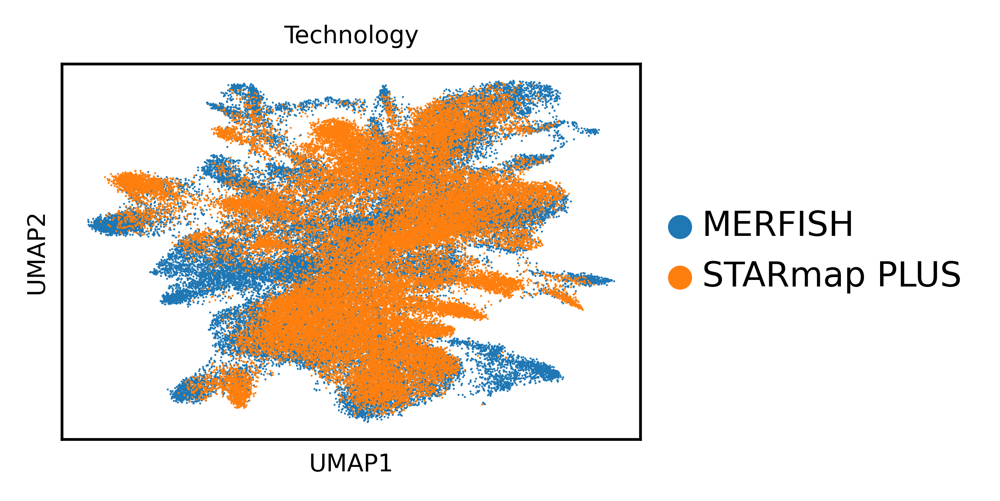

/nfs/team361/sb75/.venvs/graphst/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


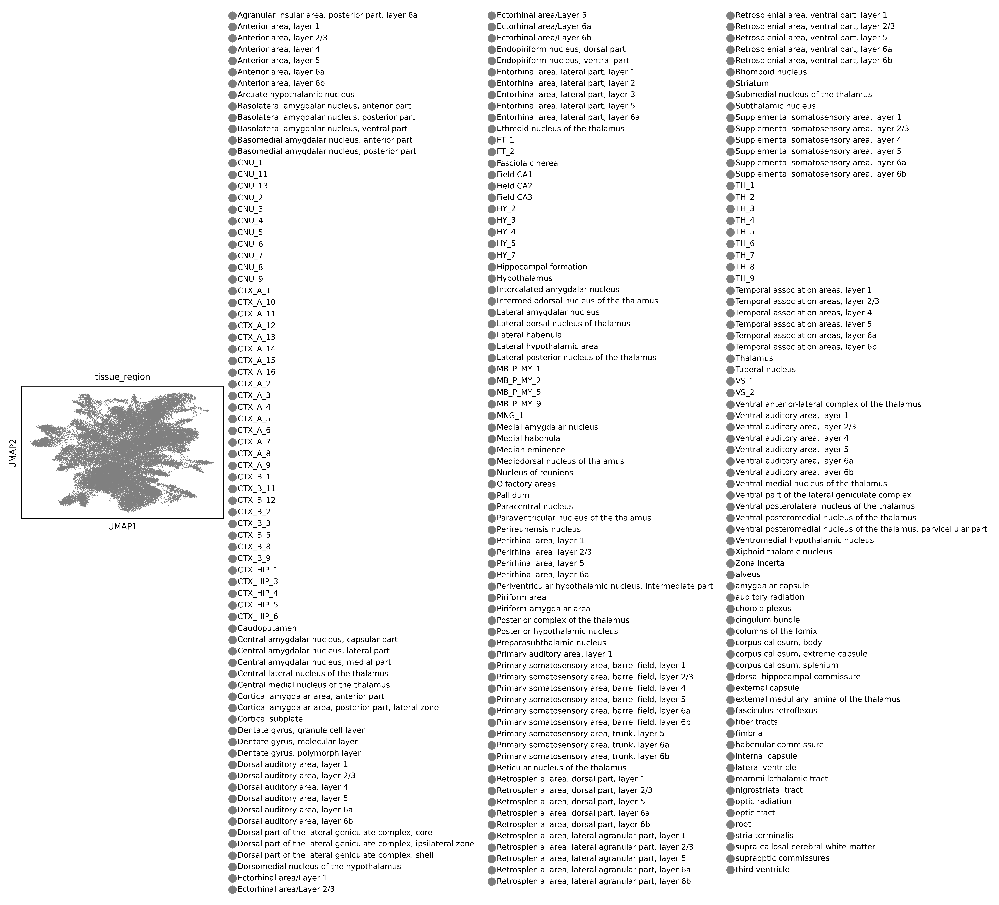

In [25]:
for emb_key in ['emb']:
    try:
        rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                         n_pcs=n_pcs, key_added=emb_key)
        rsc.tl.umap(adata, neighbors_key=emb_key)
    except NameError:
        sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                        n_pcs=n_pcs, key_added=emb_key)
        sc.tl.umap(adata, neighbors_key=emb_key)

    n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
    categories = adata.obs[batch_key].cat.categories.tolist()
    assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
    rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
    adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

    sc.pl.umap(
        adata,
        color=batch_key,
        title="Technology",
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

    for label_key in label_keys:
        sc.pl.umap(adata, color=label_key, show=False)
        for collection in plt.gca().collections:
            collection.set_rasterized(True)
        plt.savefig(
            f"{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
            format="svg", bbox_inches="tight"
        )
        plt.show()
        plt.close()

In [27]:
embedding_key = 'emb'

In [28]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded.h5ad')

print(f"Embeddings saved to {f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded.h5ad'} in obsm['{embedding_key}']")

Embeddings saved to /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/graphst/mmb0-1b_smb1-1b_1p_embedded.h5ad in obsm['emb']


In [18]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded.h5ad')

In [19]:
latent_leiden_resolution = 0.8

In [21]:
# Plot embedding-based clusters
for emb_key in ['emb']:
    latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"
    
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=latent_cluster_key,
                      resolution=latent_leiden_resolution,
                      #flavor="igraph",
                      #n_iterations=2
                     )
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=latent_cluster_key,
                     resolution=latent_leiden_resolution,
                     #flavor="igraph",
                     #n_iterations=2
                    )

In [26]:
adata.obs[latent_cluster_key].value_counts()

emb_clusters_res_0.8
0     13804
1     10454
2      8623
3      8342
4      7439
5      5290
6      4920
7      4212
8      3808
9      3483
10     2395
11     2183
12     2130
13     1527
14     1442
15     1433
16     1336
17     1141
18      836
19      479
20      427
Name: count, dtype: int64

In [ ]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/graphst/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

/nfs/team361/sb75/.venvs/graphst/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


In [ ]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded_clustered.h5ad')